# Notebook 04: Implicit-to-Explicit Signal Calibration (Dwell Time & Scroll Depth)

## 1. Continuous Confidence Weighting
In `ml/src/data/dataset.py`, implicit reading telemetry is transformed into a continuous BPR triplet weight:
$$w_{ui} = \min\!\left(\frac{t_{ui}}{60}, 3.0\right) + 1.5 \cdot \mathbb{I}(\text{like}_{ui})$$
This notebook verifies the empirical correlation between scroll depth, dwell duration, and explicit actions (likes & bookmarks).

In [1]:
import os, sys, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Resolve repository root deterministically from ml/notebooks/
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

DATA_DIR = os.path.join(REPO_ROOT, "ml", "data", "processed")
ARTIFACTS_DIR = os.path.join(REPO_ROOT, "ml", "artifacts")
VIZ_DIR = os.path.join(REPO_ROOT, "ml", "visualizations")
plt.rcParams["figure.dpi"] = 110
from scipy import stats

df = pd.read_csv(os.path.join(DATA_DIR, "interactions.csv"))
r_pearson, p_val = stats.pearsonr(df["dwell_time_sec"], df["scroll_depth"])
r_spearman, _ = stats.spearmanr(df["dwell_time_sec"], df["scroll_depth"])

df["bpr_weight"] = np.minimum(df["dwell_time_sec"] / 60.0, 3.0) + np.where(df["is_like"] == 1, 1.5, 0.0)
df["scroll_bin"] = pd.cut(df["scroll_depth"], bins=[0, 0.25, 0.5, 0.75, 1.0], labels=["0-25%", "25-50%", "50-75%", "75-100%"])

print(f"Pearson r (dwell vs scroll)  : {r_pearson:.4f} (p = {p_val:.2e})")
print(f"Spearman rho                 : {r_spearman:.4f}")
print("\nExplicit Conversion Rates by Scroll Depth Quartile:")
conv = df.groupby("scroll_bin", observed=False).agg(
    sessions=("event_id", "count"),
    mean_dwell_s=("dwell_time_sec", "mean"),
    like_rate_pct=("is_like", lambda s: s.mean() * 100),
    bookmark_rate_pct=("is_bookmark", lambda s: s.mean() * 100),
    mean_bpr_weight=("bpr_weight", "mean"),
)
print(conv.round(2).to_string())

Pearson r (dwell vs scroll)  : 0.5586 (p = 0.00e+00)
Spearman rho                 : 0.5556

Explicit Conversion Rates by Scroll Depth Quartile:
            sessions  mean_dwell_s  like_rate_pct  bookmark_rate_pct  mean_bpr_weight
scroll_bin                                                                           
0-25%            774          5.42           0.00               0.00             0.09
25-50%           549         22.16           4.37               2.00             0.43
50-75%          1008         81.35          17.06               8.04             1.58
75-100%         2534         80.19          18.27               6.27             1.59


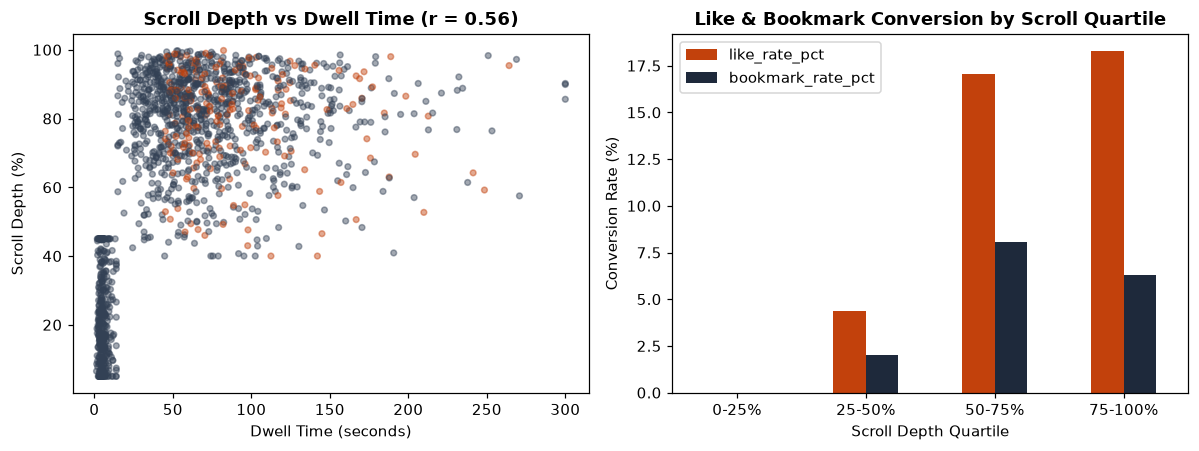

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sample_df = df.sample(min(1500, len(df)), random_state=SEED)
colors = np.where(sample_df["is_like"] == 1, "#c2410c", "#334155")
axes[0].scatter(sample_df["dwell_time_sec"], sample_df["scroll_depth"] * 100, c=colors, alpha=0.45, s=14)
axes[0].set_title(f"Scroll Depth vs Dwell Time (r = {r_pearson:.2f})", fontweight="bold")
axes[0].set_xlabel("Dwell Time (seconds)")
axes[0].set_ylabel("Scroll Depth (%)")

conv[["like_rate_pct", "bookmark_rate_pct"]].plot(kind="bar", ax=axes[1], color=["#c2410c", "#1e293b"])
axes[1].set_title("Like & Bookmark Conversion by Scroll Quartile", fontweight="bold")
axes[1].set_xlabel("Scroll Depth Quartile")
axes[1].set_ylabel("Conversion Rate (%)")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()